In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
GAMES = 1000

agents = {
    file.stem.replace("evaluation_", ""): pd.read_csv(file)
    for file in sorted(Path(f"evaluations/games_{GAMES}").glob("evaluation_*.csv"))
}

training = {
    file.stem: pd.read_csv(file)
    for file in sorted(Path("training").glob("*.csv"))
}

for name, games in agents.items():
    print(f"{name} games:", len(games))

for name, episodes in training.items():
    print(f"{name} training episodes:", len(episodes))

dqn_f11_h256_seed80_legacy_2026-11-10 games: 1000
dqn_f12_h1024_run1024x1000 games: 1000
dqn_f13_h1024_best92avg35 games: 1000
dqn_f13_h1024_failure games: 1000
mdp games: 1000
dqn_f11_h256_seed80_legacy_2026-11-10 training episodes: 2000
dqn_f12_h1024_run1024x1000 training episodes: 8000
dqn_f13_h1024_best92avg35 training episodes: 8000
dqn_f13_h1024_failure training episodes: 80000


DQN training progress

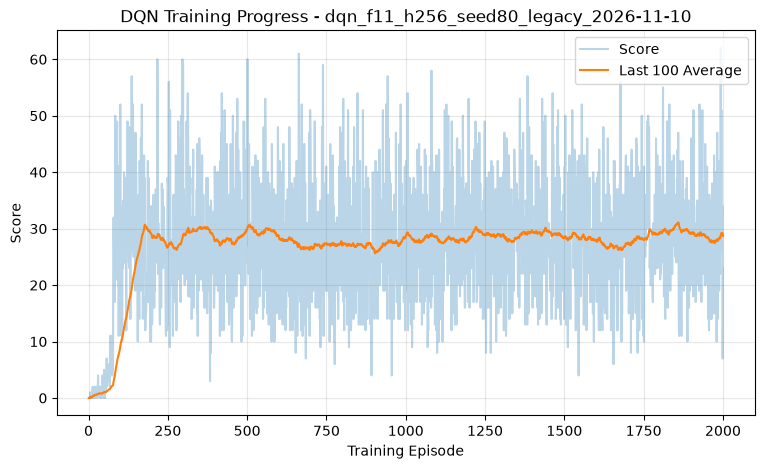

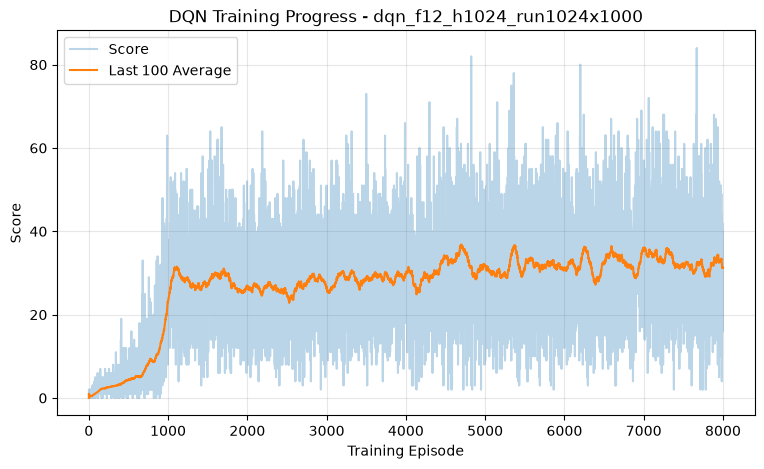

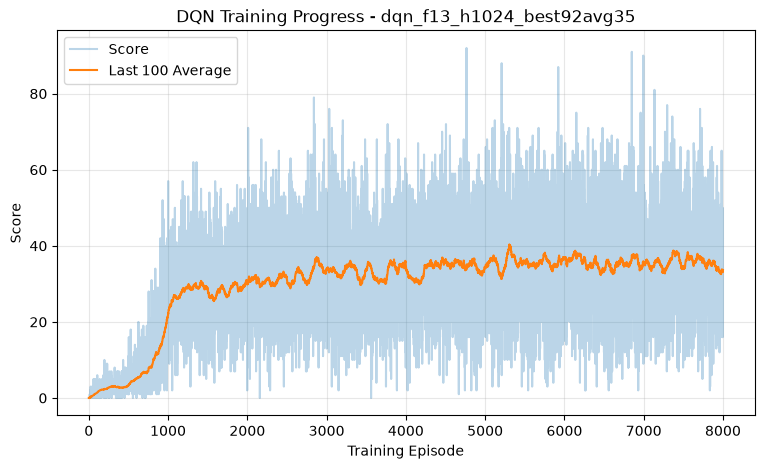

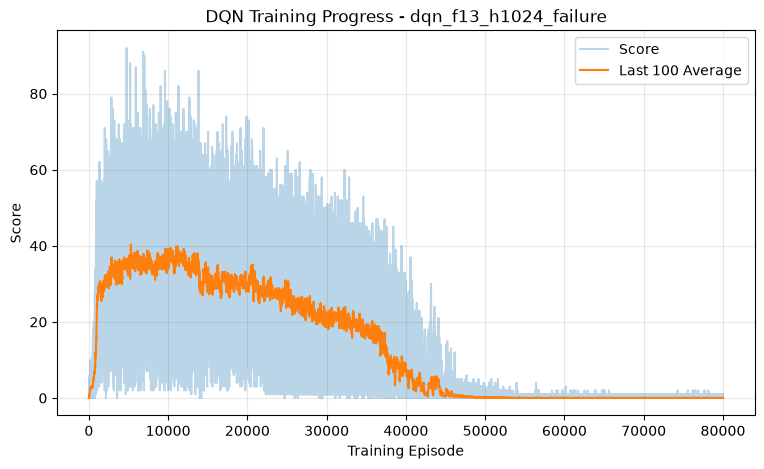

In [3]:
for name, episodes in training.items():
    plt.figure(figsize=(9, 5))

    plt.plot(
        episodes["episode"],
        episodes["score"],
        alpha=0.3,
        label="Score"
    )

    plt.plot(
        episodes["episode"],
        episodes["mean_last_100"],
        label="Last 100 Average"
    )

    plt.xlabel("Training Episode")
    plt.ylabel("Score")
    plt.title(f"DQN Training Progress - {name}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

Compare performance of all agents

In [4]:
comparison = pd.DataFrame({
    "Agent": list(agents),
    "Average Score": [
        games["score"].mean() for games in agents.values()
    ],
    "Highest Score": [
        games["score"].max() for games in agents.values()
    ],
    "Average Steps": [
        games["steps"].mean() for games in agents.values()
    ],
    "Average Reward": [
        games["total_reward"].mean() for games in agents.values()
    ],
    "Average Number of Steps to Score": [
        games["steps"].mean() /
        games["score"].mean()
        for games in agents.values()
    ],
}).sort_values("Average Score", ascending=False)

display(comparison.round(2))

,Agent,Average Score,Highest Score,Average Steps,Average Reward,Average Number of Steps to Score
2,dqn_f13_h1024_best92avg35,35.76,82,687.49,282.49,19.23
4,mdp,34.60,84,640.49,275.56,18.51
1,dqn_f12_h1024_run1024x1000,31.60,64,585.50,250.76,18.53
0,dqn_f11_h256_seed80_legacy_2026-11-10,29.31,63,529.27,233.19,18.06
3,dqn_f13_h1024_failure,0.04,2,304.04,-39.92,8001.03


Compare average scores

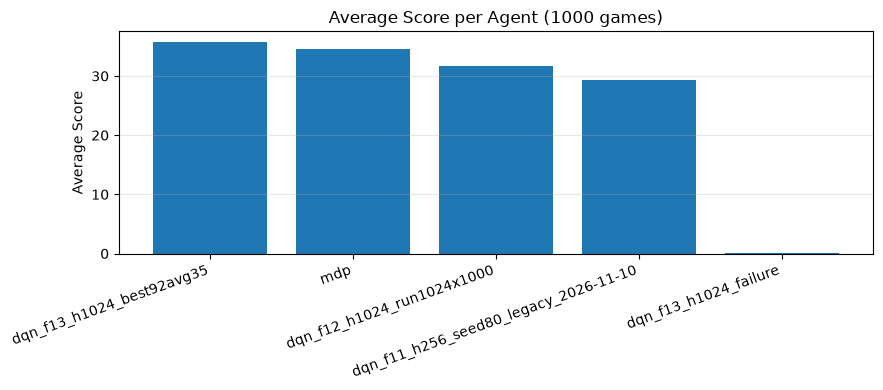

In [5]:
plt.figure(figsize=(9, 4))

plt.bar(
    comparison["Agent"],
    comparison["Average Score"]
)

plt.ylabel("Average Score")
plt.title(f"Average Score per Agent ({GAMES} games)")
plt.xticks(rotation=20, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Compare game outcomes

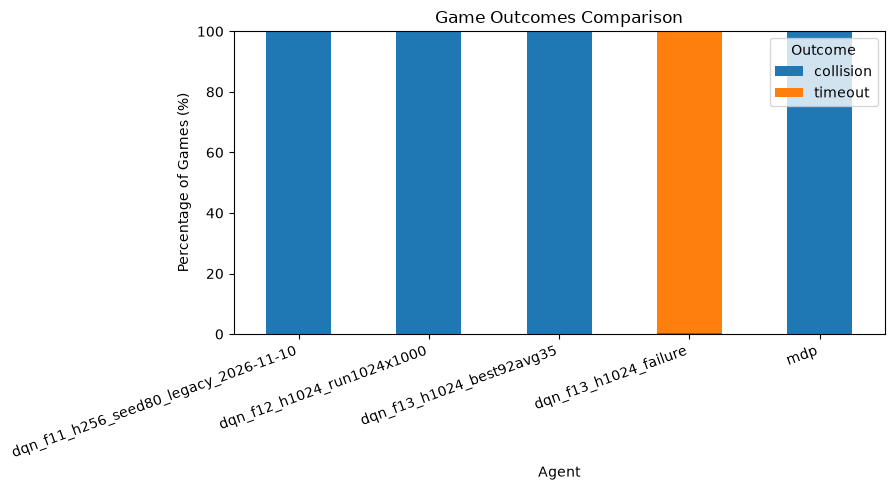

In [6]:
outcomes = pd.DataFrame({
    name: games["outcome"].value_counts(normalize=True) * 100
    for name, games in agents.items()
}).fillna(0)

outcomes.T.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.xlabel("Agent")
plt.ylabel("Percentage of Games (%)")
plt.title("Game Outcomes Comparison")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

Compare average scores across the 10, 100 and 1000 game runs

In [7]:
runs = pd.DataFrame({
    f"{run.name.replace('games_', '')} games": {
        file.stem.replace("evaluation_", ""): pd.read_csv(file)["score"].mean()
        for file in sorted(run.glob("evaluation_*.csv"))
    }
    for run in sorted(Path("evaluations").glob("games_*"), key=lambda run: int(run.name.split("_")[1]))
})

display(runs.round(2))

,10 games,100 games,1000 games
dqn_f11_h256_seed80_legacy_2026-11-10,31.9,28.93,29.31
dqn_f12_h1024_run1024x1000,31.3,32.11,31.60
dqn_f13_h1024_best92avg35,36.2,36.61,35.76
dqn_f13_h1024_failure,0.0,0.02,0.04
mdp,33.0,32.80,34.60
